In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
cellphones = pd.read_excel("cellphones_data.xlsx")
users = pd.read_excel("cellphone_users.xlsx")
ratings = pd.read_excel("cellphones_ratings.xlsx")

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


In [6]:
print("Cellphones dataset:", cellphones.shape)
print("Users dataset:", users.shape)
print("Ratings dataset:", ratings.shape)

Cellphones dataset: (33, 14)
Users dataset: (99, 7)
Ratings dataset: (990, 3)


In [7]:
print("CELLPHONES COLUMNS:")
print(cellphones.columns.tolist())

print("\nUSERS COLUMNS:")
print(users.columns.tolist())

print("\nRATINGS COLUMNS:")
print(ratings.columns.tolist())

CELLPHONES COLUMNS:
['cellphone_id', 'brand', 'model', 'operating system', 'internal memory', 'RAM', 'performance', 'main camera', 'selfie camera', 'battery size', 'screen size', 'weight', 'price(INR)', 'release date']

USERS COLUMNS:
['user_id', 'user_name', 'Region(City)', 'Salary_in_INR', 'age', 'gender', 'occupation']

RATINGS COLUMNS:
['user_id', 'cellphone_id', 'rating']


In [8]:
print("Missing values in Cellphones:")
print(cellphones.isnull().sum())

print("\nMissing values in Users:")
print(users.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

Missing values in Cellphones:
cellphone_id        0
brand               0
model               0
operating system    0
internal memory     0
RAM                 0
performance         0
main camera         0
selfie camera       0
battery size        0
screen size         0
weight              0
price(INR)          0
release date        0
dtype: int64

Missing values in Users:
user_id          0
user_name        0
Region(City)     0
Salary_in_INR    0
age              0
gender           0
occupation       0
dtype: int64

Missing values in Ratings:
user_id         0
cellphone_id    0
rating          0
dtype: int64


In [9]:
print("Duplicate rows in Cellphones:", cellphones.duplicated().sum())

print("Duplicate rows in Users:", users.duplicated().sum())

print("Duplicate rows in Ratings:", ratings.duplicated().sum())

Duplicate rows in Cellphones: 0
Duplicate rows in Users: 0
Duplicate rows in Ratings: 0


In [10]:
print("CELLPHONES DATA TYPES:")
print(cellphones.dtypes)

print("\nUSERS DATA TYPES:")
print(users.dtypes)

print("\nRATINGS DATA TYPES:")
print(ratings.dtypes)

CELLPHONES DATA TYPES:
cellphone_id          int64
brand                   str
model                   str
operating system        str
internal memory       int64
RAM                   int64
performance         float64
main camera           int64
selfie camera         int64
battery size          int64
screen size         float64
weight                int64
price(INR)          float64
release date         object
dtype: object

USERS DATA TYPES:
user_id          int64
user_name          str
Region(City)       str
Salary_in_INR    int64
age              int64
gender             str
occupation         str
dtype: object

RATINGS DATA TYPES:
user_id         int64
cellphone_id    int64
rating          int64
dtype: object


In [11]:
print("CELLPHONES NUMERICAL SUMMARY:")
print(cellphones.describe())


CELLPHONES NUMERICAL SUMMARY:
       cellphone_id  internal memory        RAM  performance  main camera  \
count      33.00000        33.000000  33.000000    33.000000    33.000000   
mean       16.00000       148.363636   6.787879     6.219091    41.333333   
std         9.66954        92.197417   2.712904     2.885472    26.350601   
min         0.00000        32.000000   3.000000     1.020000    12.000000   
25%         8.00000       128.000000   4.000000     3.800000    12.000000   
50%        16.00000       128.000000   8.000000     6.880000    50.000000   
75%        24.00000       128.000000   8.000000     7.940000    50.000000   
max        32.00000       512.000000  12.000000    11.000000   108.000000   

       selfie camera  battery size  screen size      weight     price(INR)  
count      33.000000     33.000000    33.000000   33.000000      33.000000  
mean       15.484848   4320.666667     6.433333  197.363636   54879.622727  
std        10.028463    818.746590     0.4760

In [12]:
print("CELLPHONES NUMERICAL SUMMARY:")
print(cellphones.describe())

CELLPHONES NUMERICAL SUMMARY:
       cellphone_id  internal memory        RAM  performance  main camera  \
count      33.00000        33.000000  33.000000    33.000000    33.000000   
mean       16.00000       148.363636   6.787879     6.219091    41.333333   
std         9.66954        92.197417   2.712904     2.885472    26.350601   
min         0.00000        32.000000   3.000000     1.020000    12.000000   
25%         8.00000       128.000000   4.000000     3.800000    12.000000   
50%        16.00000       128.000000   8.000000     6.880000    50.000000   
75%        24.00000       128.000000   8.000000     7.940000    50.000000   
max        32.00000       512.000000  12.000000    11.000000   108.000000   

       selfie camera  battery size  screen size      weight     price(INR)  
count      33.000000     33.000000    33.000000   33.000000      33.000000  
mean       15.484848   4320.666667     6.433333  197.363636   54879.622727  
std        10.028463    818.746590     0.4760

In [13]:
numeric_cols = cellphones.select_dtypes(include=np.number).columns.drop("cellphone_id")

for col in numeric_cols:
    Q1 = cellphones[col].quantile(0.25)
    Q3 = cellphones[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((cellphones[col] < lower) | (cellphones[col] > upper)).sum()

    print(col, ":", count, "possible outliers")

internal memory : 13 possible outliers
RAM : 0 possible outliers
performance : 0 possible outliers
main camera : 2 possible outliers
selfie camera : 7 possible outliers
battery size : 2 possible outliers
screen size : 4 possible outliers
weight : 3 possible outliers
price(INR) : 2 possible outliers


In [14]:
print("USERS NUMERICAL SUMMARY:")
print(users.describe())

USERS NUMERICAL SUMMARY:
          user_id  Salary_in_INR        age
count   99.000000      99.000000  99.000000
mean   136.373737  527464.393939  36.393939
std     81.034206   93100.704985   9.678314
min      0.000000  300000.000000  21.000000
25%     76.500000  459375.000000  29.500000
50%    128.000000  486150.000000  33.000000
75%    220.500000  601050.000000  42.000000
max    258.000000  700500.000000  61.000000


In [15]:
numeric_cols = users.select_dtypes(include=np.number).columns.drop("user_id")

for col in numeric_cols:
    Q1 = users[col].quantile(0.25)
    Q3 = users[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((users[col] < lower) | (users[col] > upper)).sum()

    print(col, ":", count, "possible outliers")
    

Salary_in_INR : 0 possible outliers
age : 2 possible outliers


In [16]:
print("RATINGS NUMERICAL SUMMARY:")
print(ratings.describe())


RATINGS NUMERICAL SUMMARY:
          user_id  cellphone_id      rating
count  990.000000    990.000000  990.000000
mean   136.373737     16.421212    6.691919
std     80.664654      9.473466    2.616552
min      0.000000      0.000000    1.000000
25%     74.000000      8.000000    5.000000
50%    128.000000     16.000000    7.000000
75%    226.000000     25.000000    9.000000
max    258.000000     32.000000   10.000000


In [17]:
Q1 = ratings["rating"].quantile(0.25)
Q3 = ratings["rating"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

count = ((ratings["rating"] < lower) | (ratings["rating"] > upper)).sum()

print("Rating:", count, "possible outliers")

Rating: 0 possible outliers


In [1]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

password = getpass("Enter your MySQL root password: ")

connection_url = URL.create(
    "mysql+mysqlconnector",
    username="root",
    password=password,
    host="localhost",
    port=3306,
    database="cellphone_analysis"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("Connected successfully!")
    print("Database:", connection.execute(text("SELECT DATABASE();")).scalar())

Enter your MySQL root password:  ········


Connected successfully!
Database: cellphone_analysis


In [4]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

cellphones = pd.read_excel("cellphones_data.xlsx")
users = pd.read_excel("cellphone_users.xlsx")
ratings = pd.read_excel("cellphones_ratings.xlsx")

print("All three datasets loaded successfully!")
print("Cellphones:", cellphones.shape)
print("Users:", users.shape)
print("Ratings:", ratings.shape)

All three datasets loaded successfully!
Cellphones: (33, 14)
Users: (99, 7)
Ratings: (990, 3)


In [3]:
cellphones.to_sql(
    name="cellphones",
    con=engine,
    if_exists="replace",
    index=False
)

print("Cellphones dataset uploaded successfully!")

Cellphones dataset uploaded successfully!


In [4]:
users.to_sql(
    name="users",
    con=engine,
    if_exists="replace",
    index=False
)

print("Users dataset uploaded successfully!")

Users dataset uploaded successfully!


In [5]:
ratings.to_sql(
    name="ratings",
    con=engine,
    if_exists="replace",
    index=False
)

print("Ratings dataset uploaded successfully!")

Ratings dataset uploaded successfully!


In [6]:
with engine.connect() as connection:
    result = connection.execute(text("SHOW TABLES;"))
    for row in result:
        print(row[0])

cellphones
ratings
users


In [7]:
with engine.connect() as connection:
    print("Cellphones:", connection.execute(text("SELECT COUNT(*) FROM cellphones")).scalar())
    print("Users:", connection.execute(text("SELECT COUNT(*) FROM users")).scalar())
    print("Ratings:", connection.execute(text("SELECT COUNT(*) FROM ratings")).scalar())

Cellphones: 33
Users: 99
Ratings: 990


In [8]:
query = """
SELECT `price(INR)`
FROM cellphones;
"""

price_data = pd.read_sql_query(query, engine)

print(price_data.head())

   price(INR)
0    37473.15
1    61057.65
2    61057.65
3    87262.65
4   104732.65


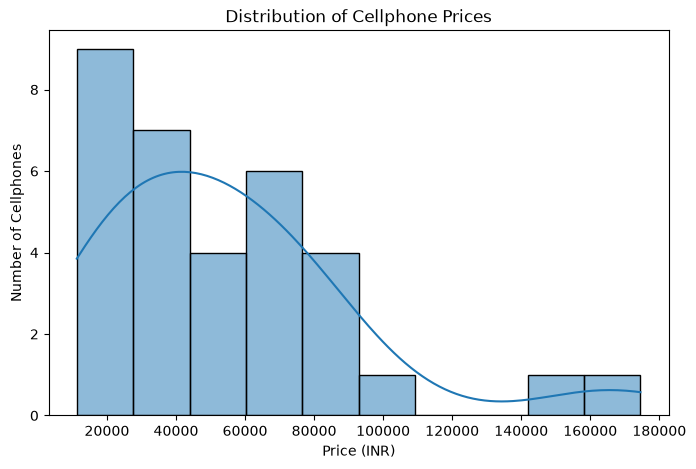

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=price_data, x="price(INR)", bins=10, kde=True)

plt.title("Distribution of Cellphone Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Cellphones")

plt.show()


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [13]:
query = """
SELECT
    COUNT(*) AS total_phones,
    MIN(`price(INR)`) AS minimum_price,
    MAX(`price(INR)`) AS maximum_price,
    AVG(`price(INR)`) AS average_price
FROM cellphones;
"""

price_stats = pd.read_sql_query(query, engine)

print(price_stats)

   total_phones  minimum_price  maximum_price  average_price
0            33       11268.15       174525.3   54879.622727


### Interpretation – Cellphone Price Distribution

- Total number of cellphones: 33.
- Minimum cellphone price: ₹11,268.15.
- Maximum cellphone price: ₹174,525.30.
- Average cellphone price: ₹54,879.62.

The analysis shows that cellphone prices have a wide range, from budget-friendly phones to expensive premium phones. The average cellphone price is approximately ₹54,880.

In [14]:
query = """
SELECT `internal memory`
FROM cellphones;
"""

memory_data = pd.read_sql_query(query, engine)

print(memory_data.head())


   internal memory
0              128
1              128
2              128
3              256
4              256


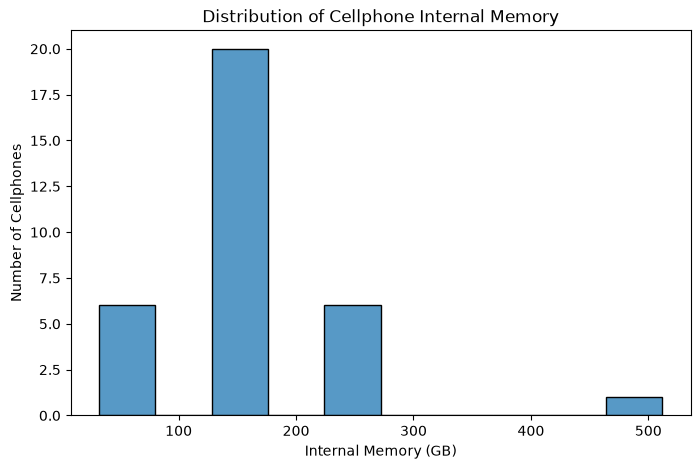

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(data=memory_data, x="internal memory", bins=10)

plt.title("Distribution of Cellphone Internal Memory")
plt.xlabel("Internal Memory (GB)")
plt.ylabel("Number of Cellphones")

plt.show()

In [17]:
query = """
SELECT
    COUNT(*) AS total_phones,
    MIN(`internal memory`) AS minimum_memory,
    MAX(`internal memory`) AS maximum_memory,
    AVG(`internal memory`) AS average_memory
FROM cellphones;
"""

memory_stats = pd.read_sql_query(query, engine)

print(memory_stats)

   total_phones  minimum_memory  maximum_memory  average_memory
0            33              32             512        148.3636


### Interpretation – Internal Memory Distribution

- Total number of cellphones: 33.
- Minimum internal memory: 32 GB.
- Maximum internal memory: 512 GB.
- Average internal memory: 148.36 GB.

The analysis shows that the internal memory of the cellphones ranges from 32 GB to 512 GB. The average internal memory is approximately 148.36 GB. This indicates that the dataset contains phones with different storage capacities.

In [18]:
query = """
SELECT `battery size`
FROM cellphones;
"""

battery_data = pd.read_sql_query(query, engine)

print(battery_data.head())

   battery size
0          2018
1          2438
2          3240
3          3065
4          4352


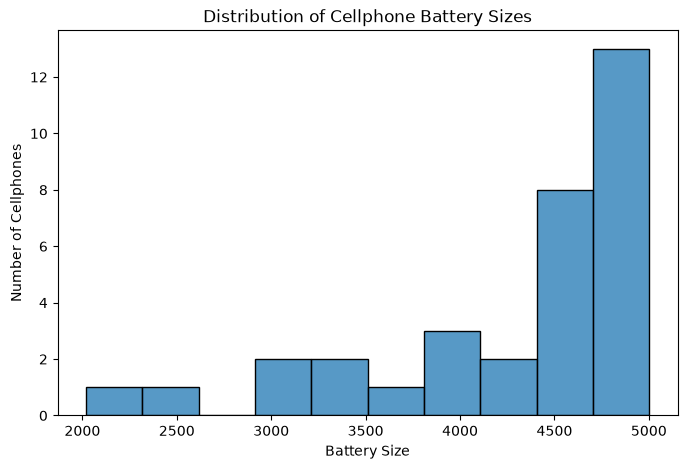

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(data=battery_data, x="battery size", bins=10)

plt.title("Distribution of Cellphone Battery Sizes")
plt.xlabel("Battery Size")
plt.ylabel("Number of Cellphones")
plt.show()

In [20]:
query = """
SELECT
    COUNT(*) AS total_phones,
    MIN(`battery size`) AS minimum_battery,
    MAX(`battery size`) AS maximum_battery,
    AVG(`battery size`) AS average_battery
FROM cellphones;
"""

battery_stats = pd.read_sql_query(query, engine)
print(battery_stats)


   total_phones  minimum_battery  maximum_battery  average_battery
0            33             2018             5003        4320.6667


### Interpretation – Battery Size Distribution

- Total number of cellphones: 33.
- Minimum battery size: 2018.
- Maximum battery size: 5003.
- Average battery size: 4320.67.

The analysis shows that cellphone battery sizes range from 2018 to 5003. The average battery size is approximately 4321. This indicates that the dataset contains phones with different battery capacities.

In [21]:
query = """
SELECT `Salary_in_INR`
FROM users;
"""

salary_data = pd.read_sql_query(query, engine)

print(salary_data.head())

   Salary_in_INR
0         570500
1         560000
2         582500
3         637500
4         456225


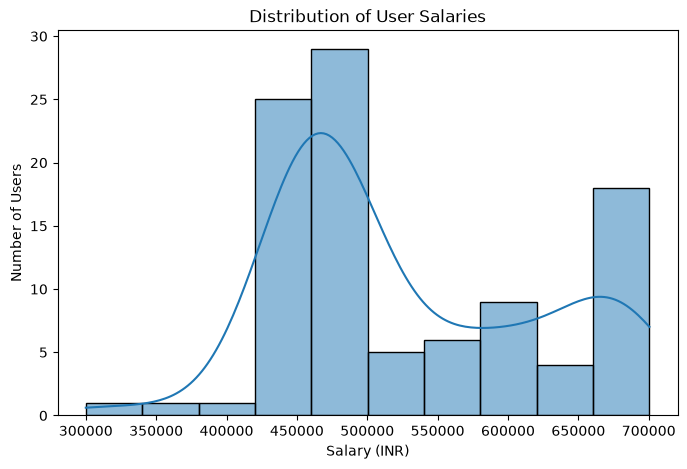

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(data=salary_data, x="Salary_in_INR", bins=10, kde=True)

plt.title("Distribution of User Salaries")
plt.xlabel("Salary (INR)")
plt.ylabel("Number of Users")
plt.show()

In [23]:
query = """
SELECT
    COUNT(*) AS total_users,
    MIN(`Salary_in_INR`) AS minimum_salary,
    MAX(`Salary_in_INR`) AS maximum_salary,
    AVG(`Salary_in_INR`) AS average_salary
FROM users;
"""

salary_stats = pd.read_sql_query(query, engine)
print(salary_stats)

   total_users  minimum_salary  maximum_salary  average_salary
0           99          300000          700500     527464.3939


### Interpretation – User Salary Distribution

- Total number of users: 99.
- Minimum salary: ₹3,00,000.
- Maximum salary: ₹7,00,500.
- Average salary: ₹5,27,464.39.

The analysis shows that user salaries range from ₹3,00,000 to ₹7,00,500. The average salary is approximately ₹5,27,464. This indicates that the dataset includes users from different income levels.

In [24]:
query = """
SELECT weight
FROM cellphones;
"""

weight_data = pd.read_sql_query(query, engine)

print(weight_data.head())

   weight
0     144
1     141
2     174
3     204
4     240


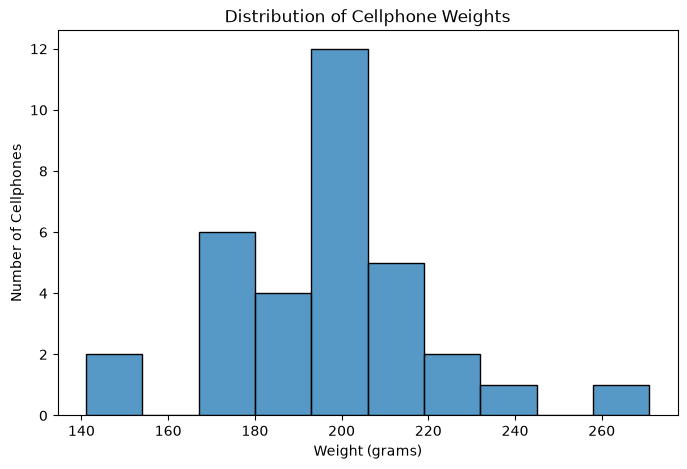

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=weight_data, x="weight", bins=10)

plt.title("Distribution of Cellphone Weights")
plt.xlabel("Weight (grams)")
plt.ylabel("Number of Cellphones")
plt.show()

In [26]:
query = """
SELECT
    COUNT(*) AS total_phones,
    MIN(weight) AS minimum_weight,
    MAX(weight) AS maximum_weight,
    AVG(weight) AS average_weight
FROM cellphones;
"""

weight_stats = pd.read_sql_query(query, engine)
print(weight_stats)

   total_phones  minimum_weight  maximum_weight  average_weight
0            33             141             271        197.3636


### Interpretation – Cellphone Weight Distribution

- Total number of cellphones: 33.
- Minimum cellphone weight: 141 grams.
- Maximum cellphone weight: 271 grams.
- Average cellphone weight: 197.36 grams.

The analysis shows that cellphone weights range from 141 grams to 271 grams. The average weight is approximately 197.36 grams. This indicates that the dataset contains both lightweight and heavier cellphones.

In [27]:
query = """
SELECT
    u.age,
    c.`price(INR)`
FROM users u
JOIN ratings r
    ON u.user_id = r.user_id
JOIN cellphones c
    ON r.cellphone_id = c.cellphone_id;
"""

age_price_data = pd.read_sql_query(query, engine)

print(age_price_data.head())

   age  price(INR)
0   38    13888.65
1   38    20614.60
2   38    46120.80
3   38    27253.20
4   38    76169.20


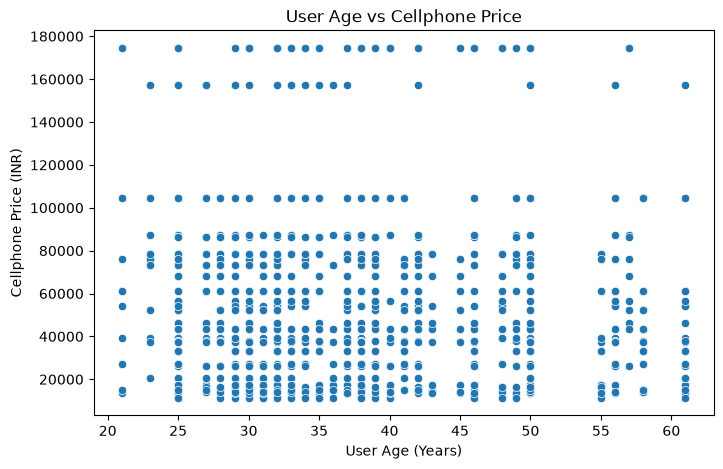

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=age_price_data,
    x="age",
    y="price(INR)"
)

plt.title("User Age vs Cellphone Price")
plt.xlabel("User Age (Years)")
plt.ylabel("Cellphone Price (INR)")
plt.show()

In [29]:
query = """
SELECT
    u.age,
    AVG(c.`price(INR)`) AS average_price
FROM users u
JOIN ratings r
    ON u.user_id = r.user_id
JOIN cellphones c
    ON r.cellphone_id = c.cellphone_id
GROUP BY u.age
ORDER BY u.age;
"""

age_price_stats = pd.read_sql_query(query, engine)
print(age_price_stats)

    age  average_price
0    21   62664.890000
1    23   72675.200000
2    25   53798.137083
3    27   52442.028333
4    28   49140.198333
5    29   49957.212000
6    30   51058.986667
7    31   39340.256250
8    32   57114.671000
9    33   56985.393000
10   34   54398.668333
11   35   57455.918333
12   36   49055.760000
13   37   56925.995000
14   38   46110.318000
15   39   58244.980000
16   40   56113.640000
17   41   48680.155000
18   42   53921.155000
19   43   38774.665000
20   45   55807.915000
21   46   54197.763333
22   48   52161.052500
23   49   56502.347500
24   50   50149.382000
25   55   38407.795000
26   56   51645.687500
27   57   71714.350000
28   58   42653.005000
29   61   44718.832500


### Interpretation – User Age vs Cellphone Price

- The analysis compares user age with the average price of cellphones rated by users.
- Users aged 23 have the highest average cellphone price of approximately ₹72,675.20.
- Users aged 43 have the lowest average cellphone price of approximately ₹38,774.67.
- The results show that average cellphone prices vary across different age groups.

This analysis suggests that users of different ages rate phones with different price ranges. However, there is no clear pattern showing that cellphone prices consistently increase or decrease with user age.

In [30]:
query = """
SELECT
    `main camera`,
    `selfie camera`,
    `price(INR)`
FROM cellphones;
"""

camera_price_data = pd.read_sql_query(query, engine)

print(camera_price_data.head())

   main camera  selfie camera  price(INR)
0           12              7    37473.15
1           12             12    61057.65
2           12             12    61057.65
3           12             12    87262.65
4           12             12   104732.65


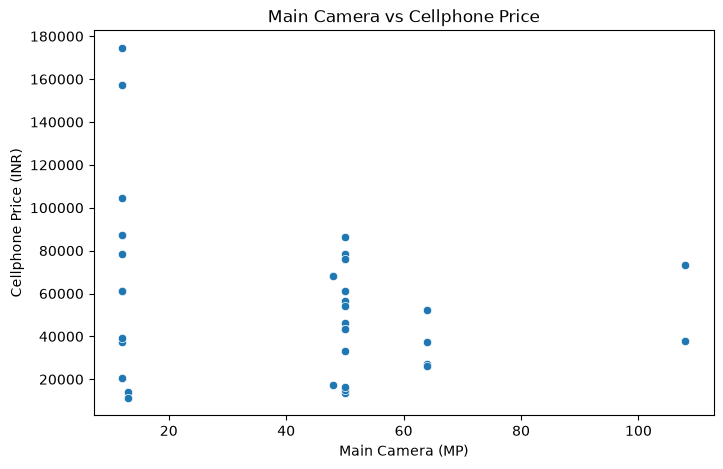

In [31]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=camera_price_data,
    x="main camera",
    y="price(INR)"
)

plt.title("Main Camera vs Cellphone Price")
plt.xlabel("Main Camera (MP)")
plt.ylabel("Cellphone Price (INR)")
plt.show()

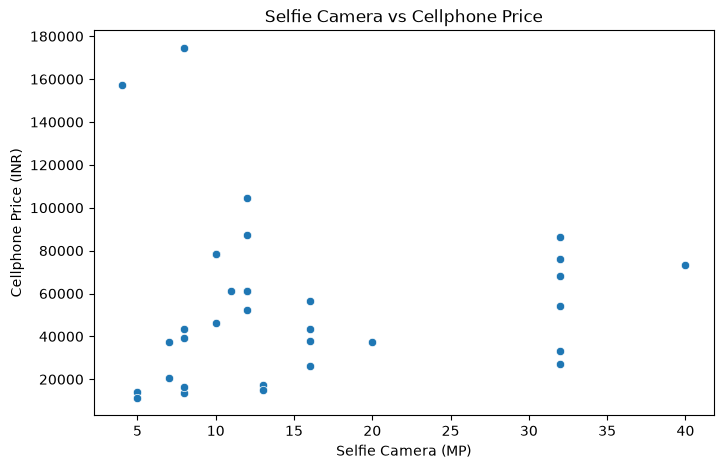

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=camera_price_data,
    x="selfie camera",
    y="price(INR)"
)

plt.title("Selfie Camera vs Cellphone Price")
plt.xlabel("Selfie Camera (MP)")
plt.ylabel("Cellphone Price (INR)")
plt.show()

In [33]:
query = """
SELECT
    `main camera`,
    AVG(`price(INR)`) AS average_price
FROM cellphones
GROUP BY `main camera`
ORDER BY `main camera`;
"""

main_camera_stats = pd.read_sql_query(query, engine)
print(main_camera_stats)


   main camera  average_price
0           12   82161.410000
1           13   12578.400000
2           48   42757.825000
3           50   48022.342308
4           64   35769.825000
5          108   55685.625000


The analysis shows that cellphone prices vary across different main camera megapixel levels. Phones with 12 MP cameras have the highest average price of ₹82,161.41, while phones with 13 MP cameras have the lowest average price of ₹12,578.40. This indicates that a higher camera megapixel count does not always result in a higher cellphone price.

In [34]:
query = """
SELECT
    `selfie camera`,
    AVG(`price(INR)`) AS average_price
FROM cellphones
GROUP BY `selfie camera`
ORDER BY `selfie camera`;
"""

selfie_camera_stats = pd.read_sql_query(query, engine)
print(selfie_camera_stats)

    selfie camera  average_price
0               4  157142.650000
1               5   12578.400000
2               7   29043.875000
3               8   57458.830000
4              10   67725.366667
5              11   61057.650000
6              12   73286.650000
7              13   16290.775000
8              16   41120.012500
9              20   37385.800000
10             32   57476.300000
11             40   73374.000000


The analysis shows that cellphone prices vary across different selfie camera megapixel levels. Phones with 4 MP selfie cameras have the highest average price of ₹1,57,142.65, while phones with 5 MP selfie cameras have the lowest average price of ₹12,578.40. This indicates that a higher selfie camera megapixel count does not always mean a higher cellphone price.

In [35]:
query = """
SELECT
    performance,
    `price(INR)`
FROM cellphones;
"""

performance_price_data = pd.read_sql_query(query, engine)
print(performance_price_data.head())

   performance  price(INR)
0         7.23    37473.15
1         7.72    61057.65
2         7.75    61057.65
3         7.94    87262.65
4         8.01   104732.65


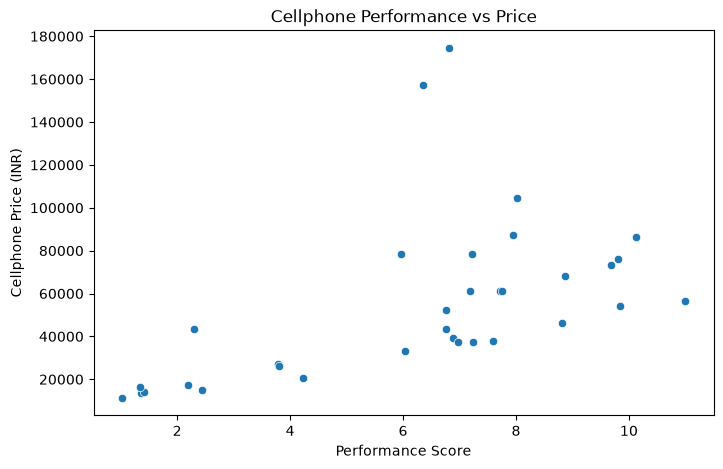

In [36]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=performance_price_data,
    x="performance",
    y="price(INR)"
)

plt.title("Cellphone Performance vs Price")
plt.xlabel("Performance Score")
plt.ylabel("Cellphone Price (INR)")
plt.show()

In [37]:
query = """
SELECT
    performance,
    AVG(`price(INR)`) AS average_price
FROM cellphones
GROUP BY performance
ORDER BY performance;
"""

performance_price_stats = pd.read_sql_query(query, engine)
print(performance_price_stats)

    performance  average_price
0          1.02       11268.15
1          1.35       16509.15
2          1.36       13451.90
3          1.42       13888.65
4          2.20       17382.65
5          2.30       43675.00
6          2.44       15198.90
7          3.79       27253.20
8          3.80       26117.65
9          4.22       20614.60
10         5.96       78527.65
11         6.04       33105.65
12         6.35      157142.65
13         6.76       47955.15
14         6.82      174525.30
15         6.88       39220.15
16         6.98       37385.80
17         7.19       61057.65
18         7.22       78527.65
19         7.23       37473.15
20         7.59       37997.25
21         7.72       61057.65
22         7.75       61057.65
23         7.94       87262.65
24         8.01      104732.65
25         8.81       46120.80
26         8.86       68133.00
27         9.68       73374.00
28         9.81       76169.20
29         9.85       53982.30
30        10.12       86214.45
31      

The analysis shows that cellphone prices vary across different performance scores. The highest average price is ₹1,74,525.30 at a performance score of 6.82, while the lowest average price is ₹11,268.15 at a performance score of 1.02. This indicates that cellphone price does not always increase with performance score. Other features and brand value may also influence the price.

In [38]:
query = """
SELECT
    c.`operating system`,
    COUNT(r.rating) AS total_ratings,
    AVG(r.rating) AS average_rating
FROM cellphones c
JOIN ratings r
    ON c.cellphone_id = r.cellphone_id
GROUP BY c.`operating system`
ORDER BY total_ratings DESC;
"""

os_rating_data = pd.read_sql_query(query, engine)
print(os_rating_data)

  operating system  total_ratings  average_rating
0          Android            825          6.5018
1              iOS            165          7.6424


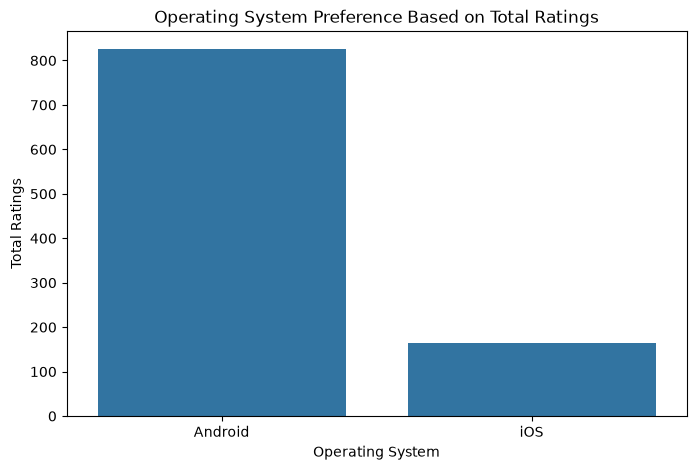

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=os_rating_data,
    x="operating system",
    y="total_ratings"
)

plt.title("Operating System Preference Based on Total Ratings")
plt.xlabel("Operating System")
plt.ylabel("Total Ratings")
plt.show()

The analysis shows that Android received 825 ratings, while iOS received 165 ratings. Therefore, Android is the most popular operating system based on the total number of ratings. However, iOS has a higher average rating of 7.64 compared to Android's 6.50. This indicates that Android is more popular in the dataset, while iOS has a higher average user rating.

In [40]:
query = """
SELECT
    `release date`,
    `price(INR)`
FROM cellphones
ORDER BY `release date`;
"""

release_price_data = pd.read_sql_query(query, engine)
print(release_price_data.head())

          release date  price(INR)
0           14/01/2021    13888.65
1           14/03/2022    86214.45
2           14/10/2021    11268.15
3           18/03/2022    37473.15
4  2021-05-10 00:00:00    37997.25


In [42]:
release_price_data["release date"] = pd.to_datetime(
    release_price_data["release date"],
    format="mixed",
    dayfirst=True
)

print(release_price_data.head())

  release date  price(INR)
0   2021-01-14    13888.65
1   2022-03-14    86214.45
2   2021-10-14    11268.15
3   2022-03-18    37473.15
4   2021-10-05    37997.25


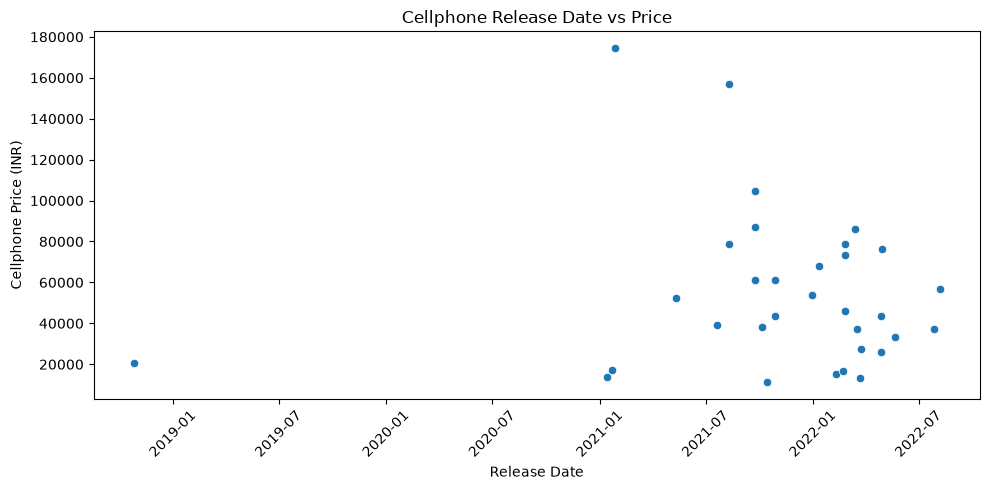

In [43]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=release_price_data,
    x="release date",
    y="price(INR)"
)

plt.title("Cellphone Release Date vs Price")
plt.xlabel("Release Date")
plt.ylabel("Cellphone Price (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The scatter plot compares cellphone release dates with their prices.

- Cellphone prices vary across different release dates.
- Some older phones have lower prices, while some newer phones have higher prices.
- Release date alone does not determine cellphone price.
- Other factors, such as brand, performance, and features, may also influence the price.

In [44]:
query = """
SELECT
    u.`Region(City)` AS region,
    c.brand,
    COUNT(r.rating) AS total_ratings,
    AVG(r.rating) AS average_rating
FROM users u
JOIN ratings r
    ON u.user_id = r.user_id
JOIN cellphones c
    ON r.cellphone_id = c.cellphone_id
GROUP BY u.`Region(City)`, c.brand
ORDER BY region, total_ratings DESC;
"""

region_brand_data = pd.read_sql_query(query, engine)

print(region_brand_data)

       region     brand  total_ratings  average_rating
0   Ahmedabad   Samsung             31          5.8065
1   Ahmedabad    Xiaomi             20          6.0000
2   Ahmedabad  Motorola             16          6.8750
3   Ahmedabad     Apple             16          7.3125
4   Ahmedabad    Google             13          5.4615
..        ...       ...            ...             ...
74       Pune    Xiaomi             10          7.7000
75       Pune      Sony              7          8.7143
76       Pune      Asus              6          6.3333
77       Pune      Vivo              4          8.5000
78       Pune      Oppo              3          8.0000

[79 rows x 4 columns]


In [45]:
query = """
SELECT region, brand, total_ratings, average_rating
FROM (
    SELECT
        u.`Region(City)` AS region,
        c.brand,
        COUNT(r.rating) AS total_ratings,
        AVG(r.rating) AS average_rating,
        ROW_NUMBER() OVER (
            PARTITION BY u.`Region(City)`
            ORDER BY COUNT(r.rating) DESC
        ) AS brand_rank
    FROM users u
    JOIN ratings r
        ON u.user_id = r.user_id
    JOIN cellphones c
        ON r.cellphone_id = c.cellphone_id
    GROUP BY u.`Region(City)`, c.brand
) AS ranked_brands
WHERE brand_rank = 1
ORDER BY region;
"""

preferred_brand_data = pd.read_sql_query(query, engine)

print(preferred_brand_data)

      region    brand  total_ratings  average_rating
0  Ahmedabad  Samsung             31          5.8065
1  Bangalore  Samsung             21          5.7619
2    Chennai  Samsung             35          7.0857
3      Delhi  Samsung             32          7.0000
4  Hyderabad  Samsung             31          6.5161
5    Kolkata  Samsung             27          6.0370
6     Mumbai  Samsung             29          5.9655
7       Pune  Samsung             31          7.5806


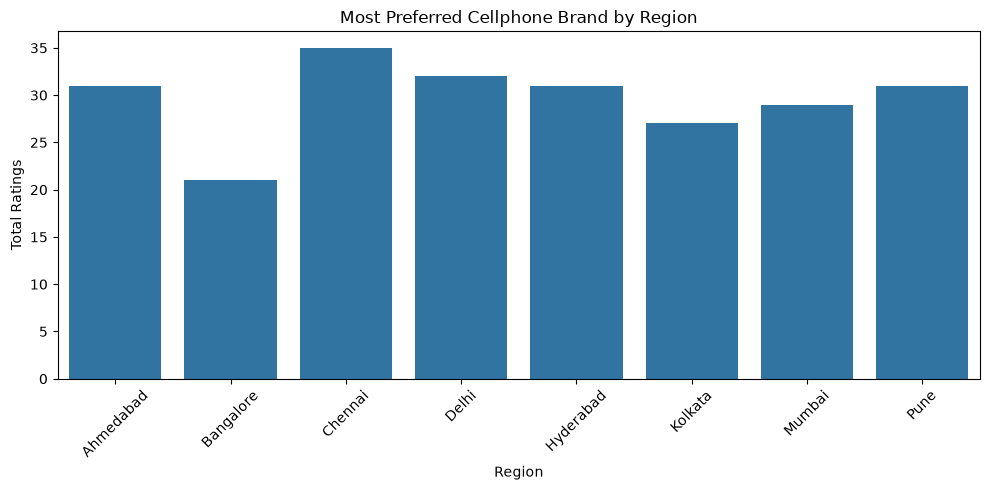

In [46]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=preferred_brand_data,
    x="region",
    y="total_ratings"
)

plt.title("Most Preferred Cellphone Brand by Region")
plt.xlabel("Region")
plt.ylabel("Total Ratings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The analysis identifies the most preferred cellphone brand in each region based on the total number of user ratings.

- Samsung is the most preferred brand in all 8 regions.
- Ahmedabad recorded 31 Samsung ratings.
- Chennai recorded the highest number of Samsung ratings, with 35.
- Samsung received strong preference across all regions.

**Conclusion:** Samsung is the most popular cellphone brand across all eight regions based on user rating counts.

In [47]:
query = """
SELECT
    u.occupation,
    AVG(c.`price(INR)`) AS average_price
FROM users u
JOIN ratings r
    ON u.user_id = r.user_id
JOIN cellphones c
    ON r.cellphone_id = c.cellphone_id
GROUP BY u.occupation
ORDER BY average_price DESC;
"""

occupation_price_data = pd.read_sql_query(query, engine)

print(occupation_price_data)

                          occupation  average_price
0                         technician   69434.515000
1                      SALES MANAGER   66722.297500
2                      master degree   66298.650000
3                             retail   65896.840000
4               System Administrator   65058.280000
5                        Warehousing   64106.165000
6   president transportation company   62996.820000
7                            banking   62682.360000
8                        ICT Officer   61861.270000
9                             worker   59275.710000
10                       Team leader   58975.808333
11                             sales   58620.585000
12                software developer   58286.471250
13                          Security   58154.718333
14                           teacher   57913.050000
15                     self employed   55572.070000
16               Computer technician   54716.040000
17                        WEB DESIGN   54410.315000
18          

In [48]:
query = """
SELECT
    u.occupation,
    AVG(c.`price(INR)`) AS average_price
FROM users u
JOIN ratings r
    ON u.user_id = r.user_id
JOIN cellphones c
    ON r.cellphone_id = c.cellphone_id
GROUP BY u.occupation
ORDER BY average_price DESC
LIMIT 3;
"""

top_3_occupations = pd.read_sql_query(query, engine)

print(top_3_occupations)

      occupation  average_price
0     technician     69434.5150
1  SALES MANAGER     66722.2975
2  master degree     66298.6500


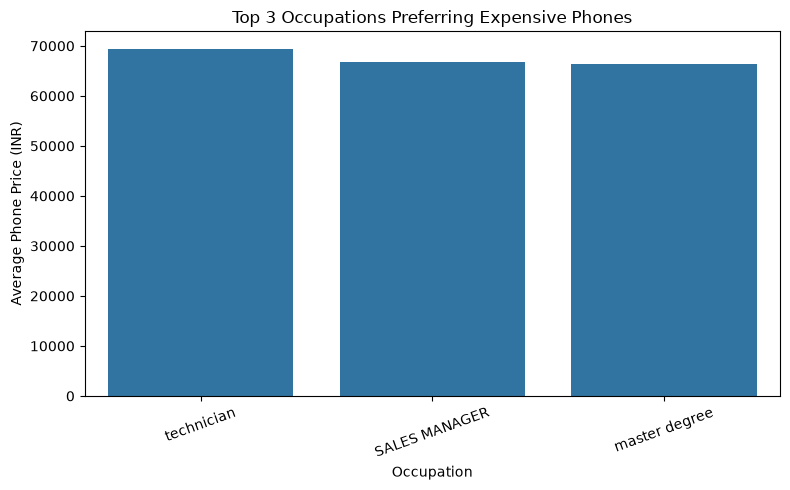

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=top_3_occupations,
    x="occupation",
    y="average_price"
)

plt.title("Top 3 Occupations Preferring Expensive Phones")
plt.xlabel("Occupation")
plt.ylabel("Average Phone Price (INR)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

The analysis compares the average prices of cellphones rated by users across different occupations.

- Technicians have the highest average cellphone price of ₹69,434.52.
- Sales Managers rank second, with an average of ₹66,722.30.
- Users with a Master Degree rank third, with an average of ₹66,298.65.

**Conclusion:** Technicians, Sales Managers, and users with a Master Degree are the top three occupation groups based on the average prices of phones they rated.

In [50]:
query = """
SELECT brand, model, total_ratings, price
FROM (
    SELECT
        c.brand,
        c.model,
        COUNT(r.rating) AS total_ratings,
        c.`price(INR)` AS price,
        ROW_NUMBER() OVER (
            PARTITION BY c.brand
            ORDER BY COUNT(r.rating) DESC
        ) AS model_rank
    FROM cellphones c
    JOIN ratings r
        ON c.cellphone_id = r.cellphone_id
    GROUP BY c.brand, c.model, c.`price(INR)`
) AS ranked_models
WHERE model_rank = 1
ORDER BY brand;
"""

popular_models_data = pd.read_sql_query(query, engine)

print(popular_models_data)

      brand               model  total_ratings      price
0     Apple   iPhone 13 Pro Max             34  104732.65
1      Asus           Zenfone 8             30   52322.65
2    Google           Pixel 6               38   43587.65
3  Motorola  Moto G Play (2021)             41   13888.65
4   OnePlus             Nord 2T             31   33105.65
5      Oppo         Find X5 Pro             30   86214.45
6   Samsung          Galaxy A32             39   17382.65
7      Sony          Xperia Pro             26  174525.30
8      Vivo             X80 Pro             24   76169.20
9    Xiaomi             11T Pro             38   37997.25


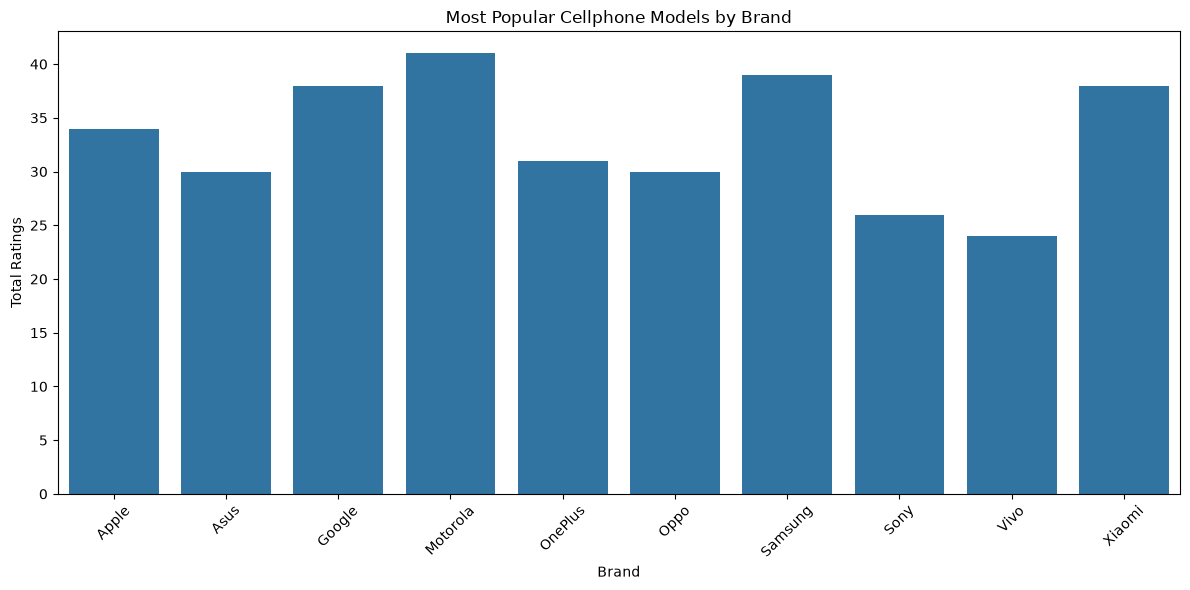

In [51]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=popular_models_data,
    x="brand",
    y="total_ratings"
)

plt.title("Most Popular Cellphone Models by Brand")
plt.xlabel("Brand")
plt.ylabel("Total Ratings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The analysis identifies the most popular cellphone model for each brand based on the total number of user ratings.

- Apple's most-rated model is iPhone 13 Pro Max.
- Asus's most-rated model is Zenfone 8.
- Google's most-rated model is Pixel 6.
- Motorola's most-rated model is Moto G Play (2021).
- OnePlus's most-rated model is Nord 2T.
- Oppo's most-rated model is Find X5 Pro.
- Samsung's most-rated model is Galaxy A32.

**Conclusion:** The analysis identifies the most-rated model for each brand. Rating counts are used as a measure of popularity, not actual purchases.


In [52]:
query = """
SELECT brand, model, average_rating
FROM (
    SELECT
        c.brand,
        c.model,
        AVG(r.rating) AS average_rating,
        ROW_NUMBER() OVER (
            PARTITION BY c.brand
            ORDER BY AVG(r.rating) DESC
        ) AS model_rank
    FROM cellphones c
    JOIN ratings r
        ON c.cellphone_id = r.cellphone_id
    GROUP BY c.brand, c.model
) AS ranked_models
WHERE model_rank = 1
ORDER BY brand;
"""

highest_rated_models = pd.read_sql_query(query, engine)

print(highest_rated_models)


      brand                model  average_rating
0     Apple            iPhone 13          8.0000
1      Asus            Zenfone 8          6.0667
2    Google         Pixel 6 Pro           7.0333
3  Motorola  Moto G Power (2022)          6.9143
4   OnePlus               10 Pro          7.2667
5      Oppo          Find X5 Pro          7.4000
6   Samsung     Galaxy S22 Ultra          7.2813
7      Sony           Xperia Pro          6.8077
8      Vivo              X80 Pro          7.1667
9    Xiaomi              11T Pro          7.3947


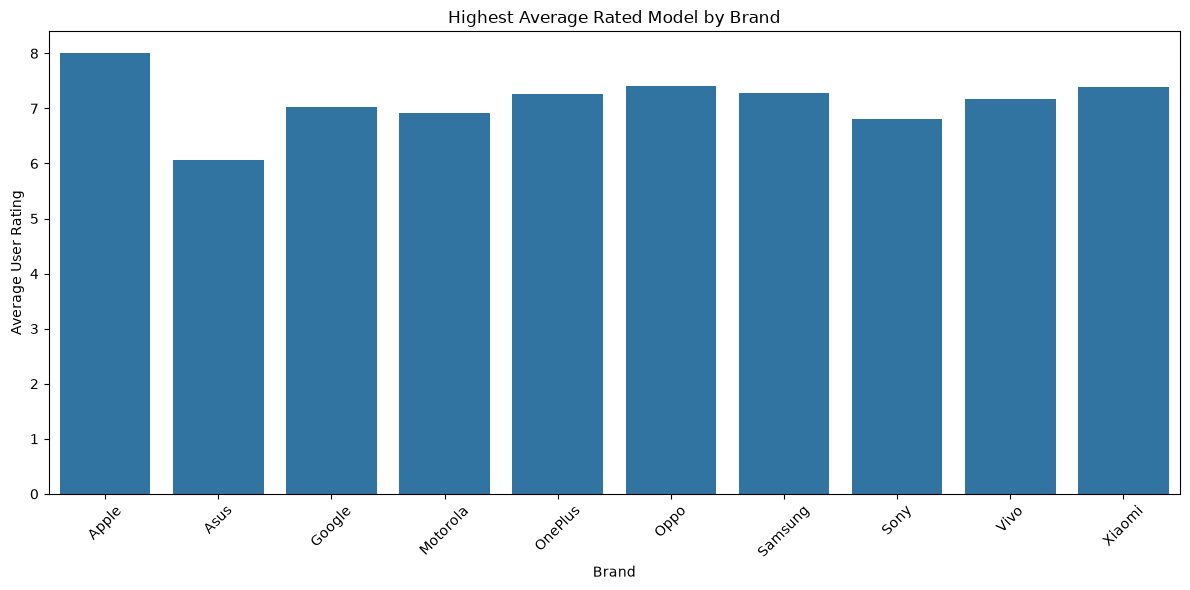

In [53]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=highest_rated_models,
    x="brand",
    y="average_rating"
)

plt.title("Highest Average Rated Model by Brand")
plt.xlabel("Brand")
plt.ylabel("Average User Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The analysis identifies the cellphone model with the highest average user rating for each brand.

- Apple's highest-rated model is iPhone 13, with an average rating of 8.00.
- Google's highest-rated model is Pixel 6 Pro, with 7.03.
- OnePlus's highest-rated model is 10 Pro, with 7.27.
- Oppo's highest-rated model is Find X5 Pro, with 7.40.
- Samsung's highest-rated model is Galaxy S22 Ultra, with 7.28.

**Conclusion:** Different brands have different highest-rated models. Apple's iPhone 13 has the highest average rating among the listed models.


In [54]:
query = """
WITH brand_counts AS (
    SELECT
        u.`Region(City)` AS region,
        c.brand,
        COUNT(r.rating) AS total_ratings
    FROM users u
    JOIN ratings r ON u.user_id = r.user_id
    JOIN cellphones c ON r.cellphone_id = c.cellphone_id
    GROUP BY u.`Region(City)`, c.brand
),
ranked_brands AS (
    SELECT
        region,
        brand,
        total_ratings,
        ROW_NUMBER() OVER (
            PARTITION BY region
            ORDER BY total_ratings DESC
        ) AS brand_rank
    FROM brand_counts
),
preferred_brands AS (
    SELECT region, brand
    FROM ranked_brands
    WHERE brand_rank = 1
),
price_stats AS (
    SELECT
        p.region,
        p.brand,
        AVG(c.`price(INR)`) AS average_price
    FROM preferred_brands p
    JOIN users u ON u.`Region(City)` = p.region
    JOIN ratings r ON r.user_id = u.user_id
    JOIN cellphones c ON c.cellphone_id = r.cellphone_id
    WHERE c.brand = p.brand
    GROUP BY p.region, p.brand
),
salary_stats AS (
    SELECT
        p.region,
        p.brand,
        AVG(user_data.Salary_in_INR) AS average_salary
    FROM preferred_brands p
    JOIN (
        SELECT DISTINCT
            u.`Region(City)` AS region,
            c.brand,
            u.user_id,
            u.Salary_in_INR
        FROM users u
        JOIN ratings r ON r.user_id = u.user_id
        JOIN cellphones c ON c.cellphone_id = r.cellphone_id
    ) AS user_data
      ON user_data.region = p.region
     AND user_data.brand = p.brand
    GROUP BY p.region, p.brand
)
SELECT
    p.region,
    p.brand AS preferred_brand,
    ps.average_price,
    ss.average_salary
FROM preferred_brands p
JOIN price_stats ps
    ON p.region = ps.region AND p.brand = ps.brand
JOIN salary_stats ss
    ON p.region = ss.region AND p.brand = ss.brand
ORDER BY p.region;
"""

region_analysis = pd.read_sql_query(query, engine)

print(region_analysis)

      region preferred_brand  average_price  average_salary
0  Ahmedabad         Samsung   60460.288710     591898.2500
1  Bangalore         Samsung   81522.507143     499298.7143
2    Chennai         Samsung   49090.700000     520394.2308
3      Delhi         Samsung   58041.345312     523390.0000
4  Hyderabad         Samsung   59102.137097     526792.5000
5    Kolkata         Samsung   70611.151852     489303.8462
6     Mumbai         Samsung   55699.179310     562779.5455
7       Pune         Samsung   45782.670968     489327.0833


In [65]:
with engine.connect() as connection:
    print("Cellphones:", connection.execute(text("SELECT COUNT(*) FROM cellphones")).scalar())
    print("Users:", connection.execute(text("SELECT COUNT(*) FROM users")).scalar())
    print("Ratings:", connection.execute(text("SELECT COUNT(*) FROM ratings")).scalar())

Cellphones: 33
Users: 99
Ratings: 990
